In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np  
import pandas as pd
import seaborn as sns
from sklearn.metrics import log_loss

from iml_feature_effects import load_parole_violators, load_german_credit, load_heart_failure

os.chdir("..")

In [2]:
df = pd.read_csv("results/scores.csv")
df["alpha"] = df["model"].str.split("_").str[-1].astype(float)

In [3]:
datasets = [load_parole_violators(), load_german_credit(), load_heart_failure()]
baselines = {ds.name: log_loss(ds.y, np.full(len(ds.y), ds.y.mean())) for ds in datasets}

In [4]:
ds = df.groupby(["dataset", "alpha"])[["train_log_loss", "test_log_loss"]].mean().reset_index()

long = ds.melt(
    id_vars=["dataset", "alpha"],
    value_vars=["train_log_loss", "test_log_loss"],
    var_name="split",
    value_name="log_loss",
)
long["split"] = long["split"].str.replace("_log_loss", "")

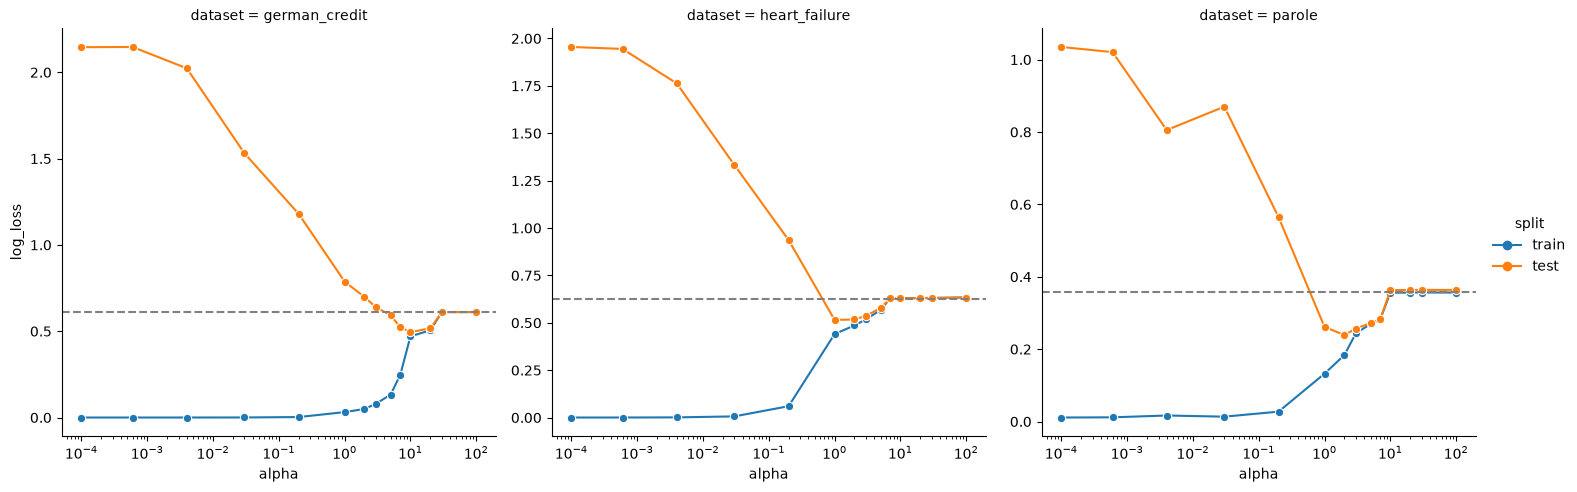

In [5]:
g = sns.relplot(
    data=long, x="alpha", y="log_loss", hue="split", col="dataset",
    kind="line", marker="o", facet_kws={"sharey": False},
)

for name, ax in g.axes_dict.items():
    ax.axhline(baselines[name], ls="--", c="grey")

g.set(xscale="log")
plt.show()